# Predicting Face Counts


## Imports


In [ ]:
import cv2
import numpy as np
import pandas as pd
import IPython.display as display

from pathlib import Path
from PIL import Image
from cv2.typing import MatLike

In [3]:
DATA_DIR = Path("data")
TRAIN_IMG_DIR = DATA_DIR / "train"
TEST_IMG_DIR = DATA_DIR / "test"
HAAR_XML_PATH = "haarcascade_frontalface_default.xml"

In [4]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

In [5]:
print(train_df.columns)
print(train_df['type'].value_counts())

Index(['image_id', 'type', 'count'], dtype='str')
type
faces    2861
coins     723
Name: count, dtype: int64


In [6]:
# filter to leave only the "face" type
train_df = train_df[train_df['type'] == 'faces']
print(train_df['type'].value_counts())
print(len(train_df))

type
faces    2861
Name: count, dtype: int64
2861


In [12]:
img = cv2.imread(str(TRAIN_IMG_DIR / train_df.iloc[0]['image_id']) + ".jpg")

if img is None:
    raise ValueError("Could not read image")

print(img.shape)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print(gray.shape)
print(type(gray))

(408, 612, 3)
(408, 612)
<class 'numpy.ndarray'>


In [ ]:
def render_cv_image(image: MatLike | None) -> None:
    if image is None:
        raise ValueError("Image is None")
    # Convert BGR to RGB (OpenCV uses BGR by default)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    # Convert to PIL Image
    pil_image = Image.fromarray(image_rgb)
    # Display the image in the notebook
    display.display(pil_image)

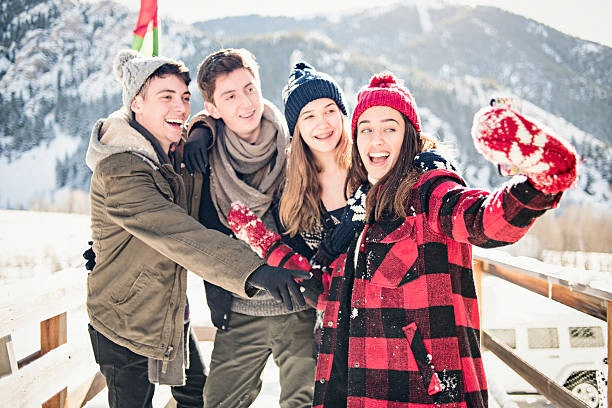

In [19]:
render_cv_image(img)

## Model


In [21]:
face_cascade = cv2.CascadeClassifier(HAAR_XML_PATH)

In [37]:
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)

In [38]:
print(f"Found {len(faces)} faces")

Found 5 faces


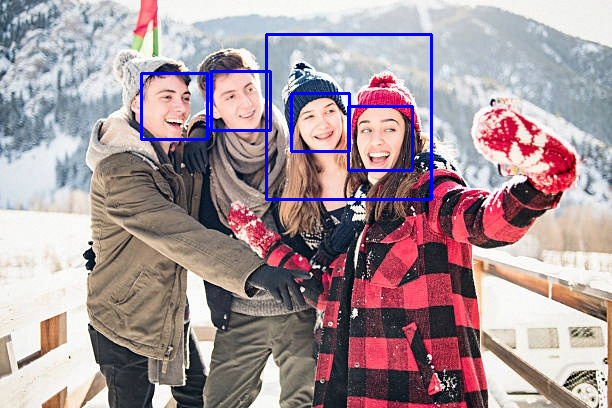

In [ ]:
for (x, y, w, h) in faces:
    if img is None:
        raise ValueError("Image is None")
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)

render_cv_image(img)

In [40]:
def count_faces(image_path: Path) -> int:
    img = cv2.imread(str(image_path))
    if img is None:
        raise ValueError(f"Could not read image at {image_path}")
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=3)
    
    return len(faces)

## Evaluating


In [41]:
train_df["predicted_count"] = train_df["image_id"].apply(lambda img_id: count_faces(TRAIN_IMG_DIR / f"{img_id}.jpg"))

In [43]:
# calculate MCRMSE: Mean Columnwise Root Mean Square Error
train_df["squared_error"] = np.square(train_df["predicted_count"] - train_df["count"])
mcrmse = np.sqrt(train_df["squared_error"].mean())
print(f"MCRMSE: {mcrmse}")

MCRMSE: 2.6601779380346517
